# 1. Importing libraries and dataset and dictionary

In [62]:
from sklearn.decomposition import PCA 
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn import metrics      
import sklearn.preprocessing as preproc

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

In [63]:
# Importing Dataset
df = pd.read_csv("Salary_Data_Based_country_and_race.csv", index_col="Unnamed: 0")
# Renaming columns
df.columns = df.columns.str.replace(" ","_").str.lower()
# Printing first 5 rows
df.head()

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,UK,White
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,USA,Hispanic
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,Canada,White
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,USA,Hispanic
4,52.0,Male,Master's,Director,20.0,200000.0,USA,Asian


In [64]:
# Inspecting Dataset
print(f"The dataframe contains {df.isnull().sum().sum()} null values.")
print("=============== Total number of null values in each feature  ===============")
df_null = df.isnull().sum()
df_null = df_null[df_null>0]
df_null


The dataframe contains 17 null values.
=============== Total number of null values in each feature  ===============


age                    2
gender                 2
education_level        3
job_title              2
years_of_experience    3
salary                 5
dtype: int64

In [65]:
# Dropping null values
df = df.dropna()

# Reseting index
df.reset_index(drop =True)

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,UK,White
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,USA,Hispanic
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,Canada,White
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,USA,Hispanic
4,52.0,Male,Master's,Director,20.0,200000.0,USA,Asian
...,...,...,...,...,...,...,...,...
6693,49.0,Female,PhD,Director of Marketing,20.0,200000.0,UK,Mixed
6694,32.0,Male,High School,Sales Associate,3.0,50000.0,Australia,Australian
6695,30.0,Female,Bachelor's Degree,Financial Manager,4.0,55000.0,China,Chinese
6696,46.0,Male,Master's Degree,Marketing Manager,14.0,140000.0,China,Korean


In [66]:
# Dataframe shape
print(f"The dataframe contains {df.shape[0]} rows / recods, and {df.shape[1]} features / variables.")

The dataframe contains 6698 rows / recods, and 8 features / variables.


In [67]:
# Checking data types
df.dtypes

age                    float64
gender                     str
education_level            str
job_title                  str
years_of_experience    float64
salary                 float64
country                    str
race                       str
dtype: object

# Data Inspection and Cleaning

In [68]:
df["education_level"] = np.where(df["education_level"]=="Master's","Master's Degree",
         np.where(df["education_level"] == "Bachelor's","Bachelor's Degree",
         np.where(df["education_level"] == "phD","PhD",df["education_level"])))

In [69]:
df["race"].value_counts()

race
White               1962
Asian               1603
Korean               457
Australian           452
Chinese              444
Black                437
African American     354
Mixed                334
Welsh                333
Hispanic             322
Name: count, dtype: int64

In [70]:
df["country"].unique()

<ArrowStringArray>
['UK', 'USA', 'Canada', 'China', 'Australia']
Length: 5, dtype: str

In [71]:
np.unique(df["gender"])

array(['Female', 'Male', 'Other'], dtype=object)

----

# EDA visualizations

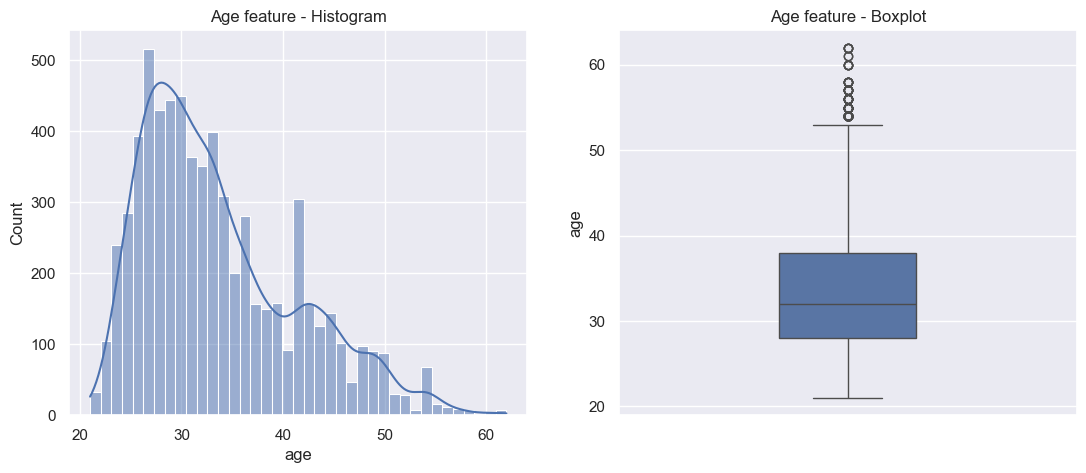

,count,mean,std,min,25%,50%,75%,max
age,6698.0,33.623022,7.615784,21.0,28.0,32.0,38.0,62.0


In [72]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["age"], kde=True)
plt.title("Age feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["age"], width=0.3)
plt.title("Age feature - Boxplot")
plt.show()

df[["age"]].describe().T

**Findings:**

---

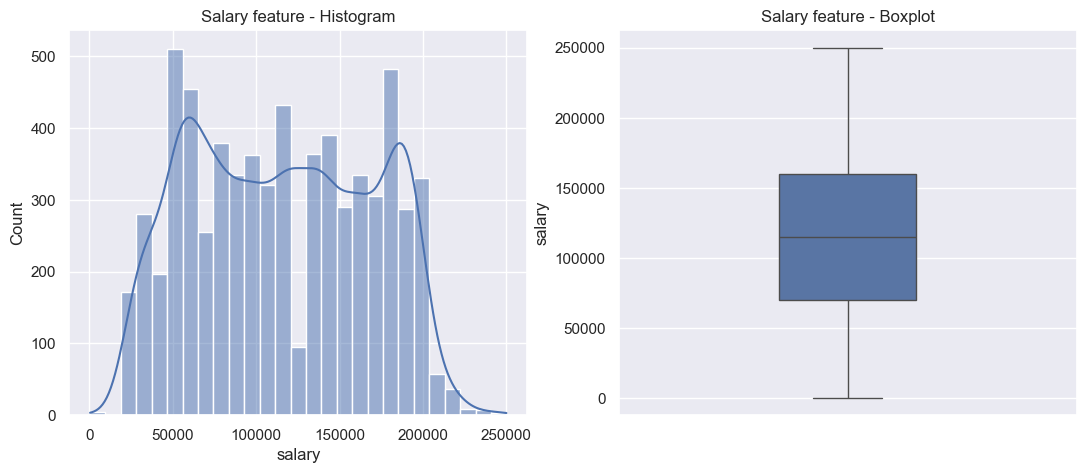

,count,mean,std,min,25%,50%,75%,max
age,6698.0,33.623022,7.615784,21.0,28.0,32.0,38.0,62.0


In [73]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["salary"], kde=True)
plt.title("Salary feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["salary"], width=0.3)
plt.title("Salary feature - Boxplot")
plt.show()

df[["age"]].describe().T

**Findings:**

---

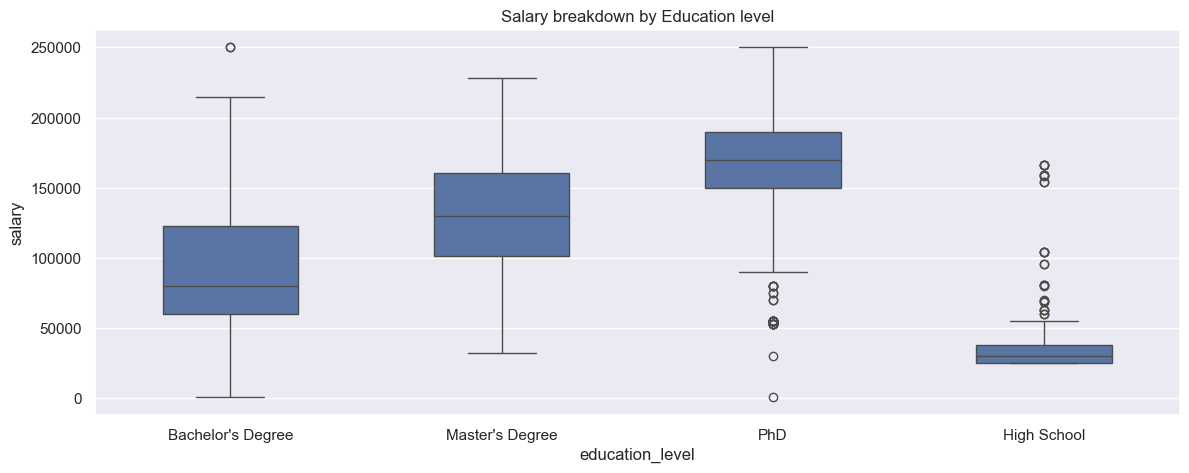

In [74]:
plt.figure(figsize=(14,5))
sns.boxplot(data=df, y="salary", x="education_level", width=0.5)
plt.title("Salary breakdown by Education level")
plt.show()

----

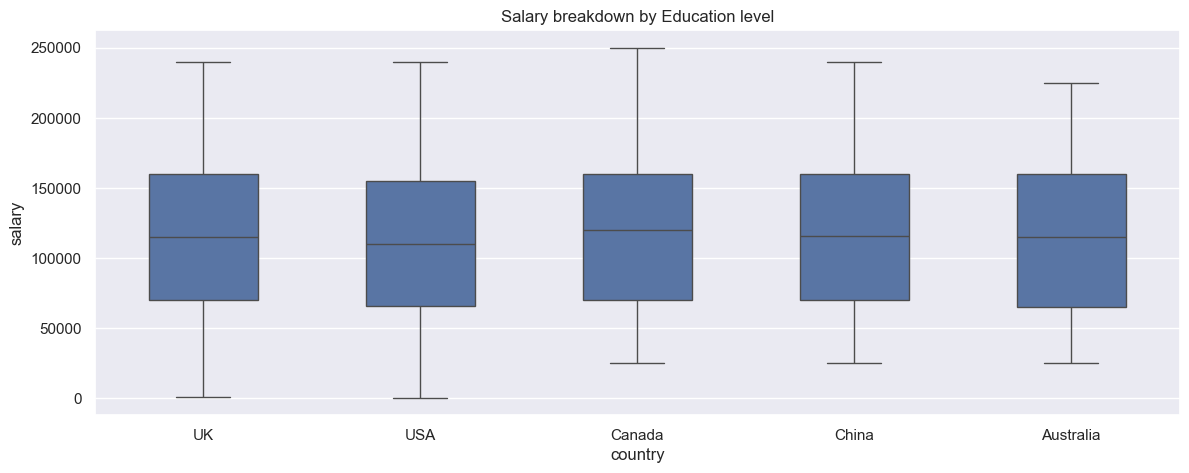

In [75]:
plt.figure(figsize=(14,5))
sns.boxplot(data=df, y="salary", x="country", width=0.5)
plt.title("Salary breakdown by Education level")
plt.show()

----

# Encoding

In [76]:
gender = {"Male":0, "Female":1}
df["gender"] = df["gender"].map(gender)

In [80]:
education = {"Bachelor's Degree":1, 'High School':0, "Master's Degree":2, 'PhD':3}
df["education_level"] = df["education_level"].map(education)

In [120]:
df1 = df.groupby("job_title")["salary"].median().sort_values().reset_index()


dic_job = {}
for i in range(len(df1["job_title"])):
    dic_job[df1["job_title"].iloc[i]] = i

df["job_title"] = df["job_title"].map(dic_job)

In [130]:
countries = {"USA":0, "Canada":1, "UK":2, "Australia":3, "China": 4}
df["country"] = df["country"].map(countries)

In [ ]:
df[]

In [145]:
dic_race

{'White': 0,
 'Asian': 1,
 'Korean': 2,
 'Australian': 3,
 'Chinese': 4,
 'Black': 5,
 'African American': 6,
 'Mixed': 7,
 'Welsh': 8,
 'Hispanic': 9}

In [147]:
df1 = df.groupby("race")["salary"].count().sort_values(ascending=False).reset_index()


dic_race = {}
for i in range(len(df1["race"])):
    dic_race[df1["race"].iloc[i]] = i

df["race"] = df["race"].map(dic_race)

---

### Building Machine Learning models

In [148]:
df

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,0.0,1,86,5.0,90000.0,2,0
1,28.0,1.0,2,130,3.0,65000.0,0,9
2,45.0,0.0,3,163,15.0,150000.0,1,0
3,36.0,1.0,1,6,7.0,60000.0,0,9
4,52.0,0.0,2,185,20.0,200000.0,0,1
...,...,...,...,...,...,...,...,...
6699,49.0,1.0,3,165,20.0,200000.0,2,7
6700,32.0,0.0,0,6,3.0,50000.0,3,3
6701,30.0,1.0,1,137,4.0,55000.0,4,4
6702,46.0,0.0,2,138,14.0,140000.0,4,2
